# **Kaggle Machine Learning Competition**

Проект решения соревнования по машинному обучению на [Kaggle](https://www.kaggle.com/) - [Spaceship Titanic](https://www.kaggle.com/competitions/spaceship-titanic/overview).

Реализованы 4 базовые модели:
* Random Forest
* XGBoost
* LightGBM
* CatBoost

Подобраны гиперпараметры для каждой модели с использованием [Optuna](https://optuna.org/).

Кросс-валидация с помощью [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html).

Реализован стекинг на основе 4 моделей с лучшими параметрами и мета-модели логистической регрессии.

В директории *Output* создаётся 6 файлов с предсказаниями тестовой выборки, они названы в соответствии с решающей моделью.

На момент 30.08.26 лучшим является **Accuracy = 0.80710** 

**Top 290-300 / Best 18%**

# Importing libraries and modules

In [57]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import optuna
import time

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

In [58]:
df = pd.read_csv('/kaggle/input/competitions/spaceship-titanic/train.csv')
df_test = pd.read_csv('/kaggle/input/competitions/spaceship-titanic/test.csv')
print(f'Dataset shape: {df.shape[0]} x {df.shape[1]}')

Dataset shape: 8693 x 14


# Exploratory Data Analysis

Проведем разведочный анализ данных на всём train. Анализ не должен делать какие-либо изменения в df, за это будут отвечать трансформеры, предназначенные для создания новых признаков по существующим, заполнения пропусков и подачи в модель в нужном виде. 

Будут созданы временные датасеты, копирующие основной train, с особыми признаками, позволяющие оценить их корреляцию с остальными.

В процессе обучения моделей будет использована кросс-валидация, и обрабатываться данные будут именно по фолдам. Модели будут обучаться на одном наборе фолдов, делать предсказания на оставшемся фолде. Кастомные трансформеры данных будут иметь 2 метода: fit и transform, что позволит запомнить закономерности на обучающих фолдах и применить их на валидационном.

In [59]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


Оценим типы данных и количество пропусков по каждому признаку:

In [60]:
print(f'Data types in dataset:\n\n{df.dtypes}\n\n')
print(f'Missing values:\n\n{df.isna().sum()}')

Data types in dataset:

PassengerId      object
HomePlanet       object
CryoSleep        object
Cabin            object
Destination      object
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name             object
Transported        bool
dtype: object


Missing values:

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64


Оценим баланс классов в обучающей выборке:

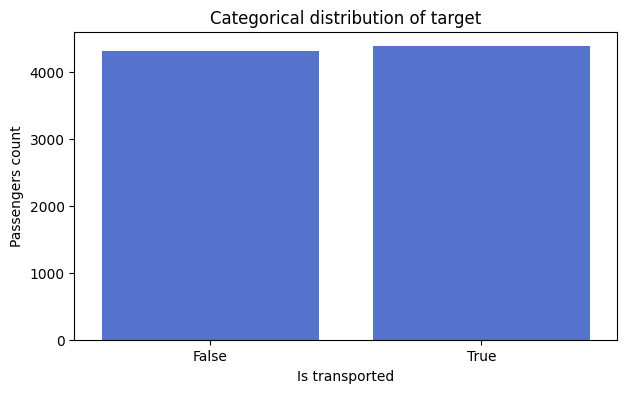

In [61]:
plt.figure(figsize=(7,4))
sns.countplot(data=df, x=df['Transported'], color='royalblue')
plt.xlabel('Is transported')
plt.ylabel('Passengers count')
plt.title('Categorical distribution of target')
plt.show()

Рассмотрим распределение возрастов, а также факт перемещения в зависимости от значения:

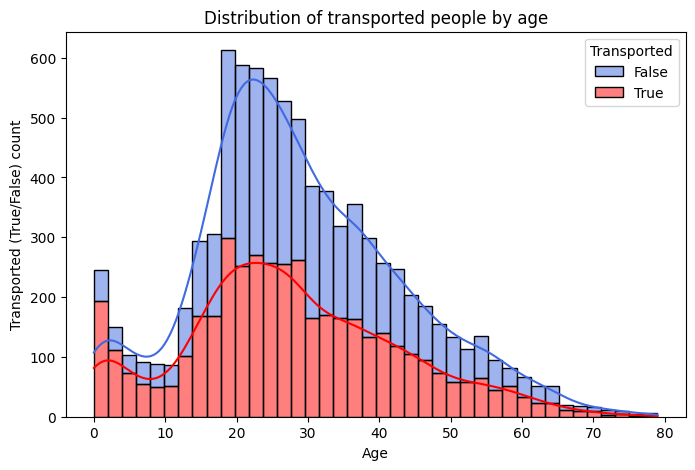

In [62]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,
             x='Age',
             hue='Transported',
             kde=True,
             bins=40,
             multiple='stack',
             palette={False: 'royalblue', True: 'red'}
            )
plt.title('Distribution of transported people by age')
plt.ylabel('Transported (True/False) count')
plt.xlabel('Age')
plt.show()

Нужно посмотреть на график с заполнением. Он наглядно покажет отношение фактов перемещений в зависимости от возраста:

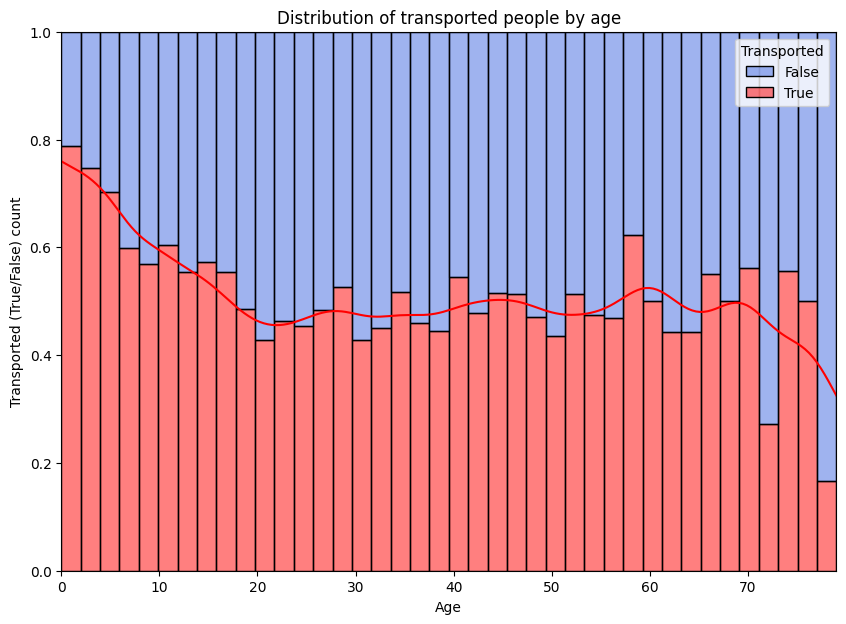

In [63]:
plt.figure(figsize=(10,7))
sns.histplot(data=df,
             x='Age',
             hue='Transported',
             kde=True,
             bins=40,
             multiple='fill',
             palette={False: 'royalblue', True: 'red'}
            )
plt.title('Distribution of transported people by age')
plt.ylabel('Transported (True/False) count')
plt.xlabel('Age')
plt.show()

Дети перемещались чаще, чем остальные. Заметно также падение на высоком значении возраста.

Рассмотрим баланс объектов отправления и мест назначения:

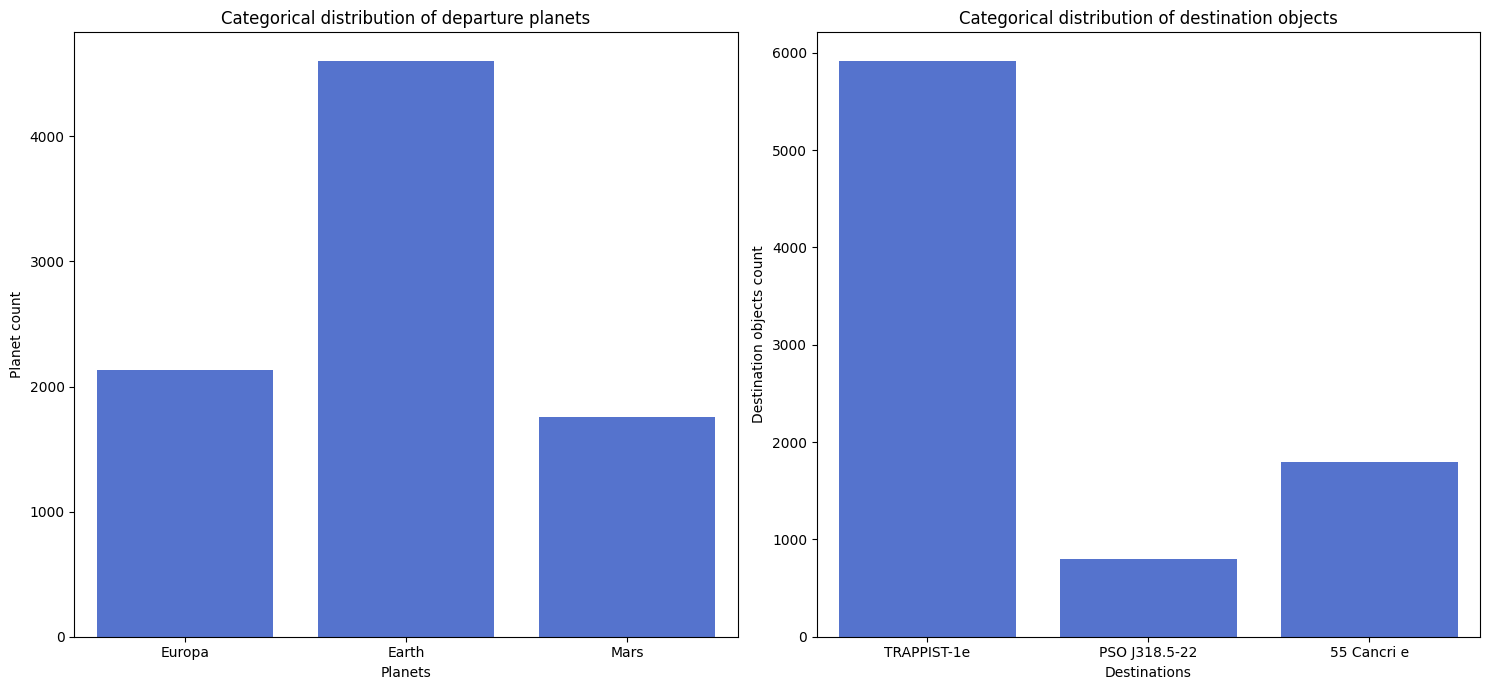

In [64]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
ax = ax.flatten()

sns.countplot(data=df, x='HomePlanet', color='royalblue', ax=ax[0])
ax[0].set_title('Categorical distribution of departure planets')
ax[0].set_xlabel('Planets')
ax[0].set_ylabel('Planet count')

sns.countplot(data=df, x='Destination', color='royalblue', ax=ax[1])
ax[1].set_title('Categorical distribution of destination objects')
ax[1].set_xlabel('Destinations')
ax[1].set_ylabel('Destination objects count')

plt.tight_layout()
plt.show()

Рассмотрим распределение людей, которые тратили средства на какие-либо услуги (график справа), а также выделим тех, кто ничего не тратил (график слева):

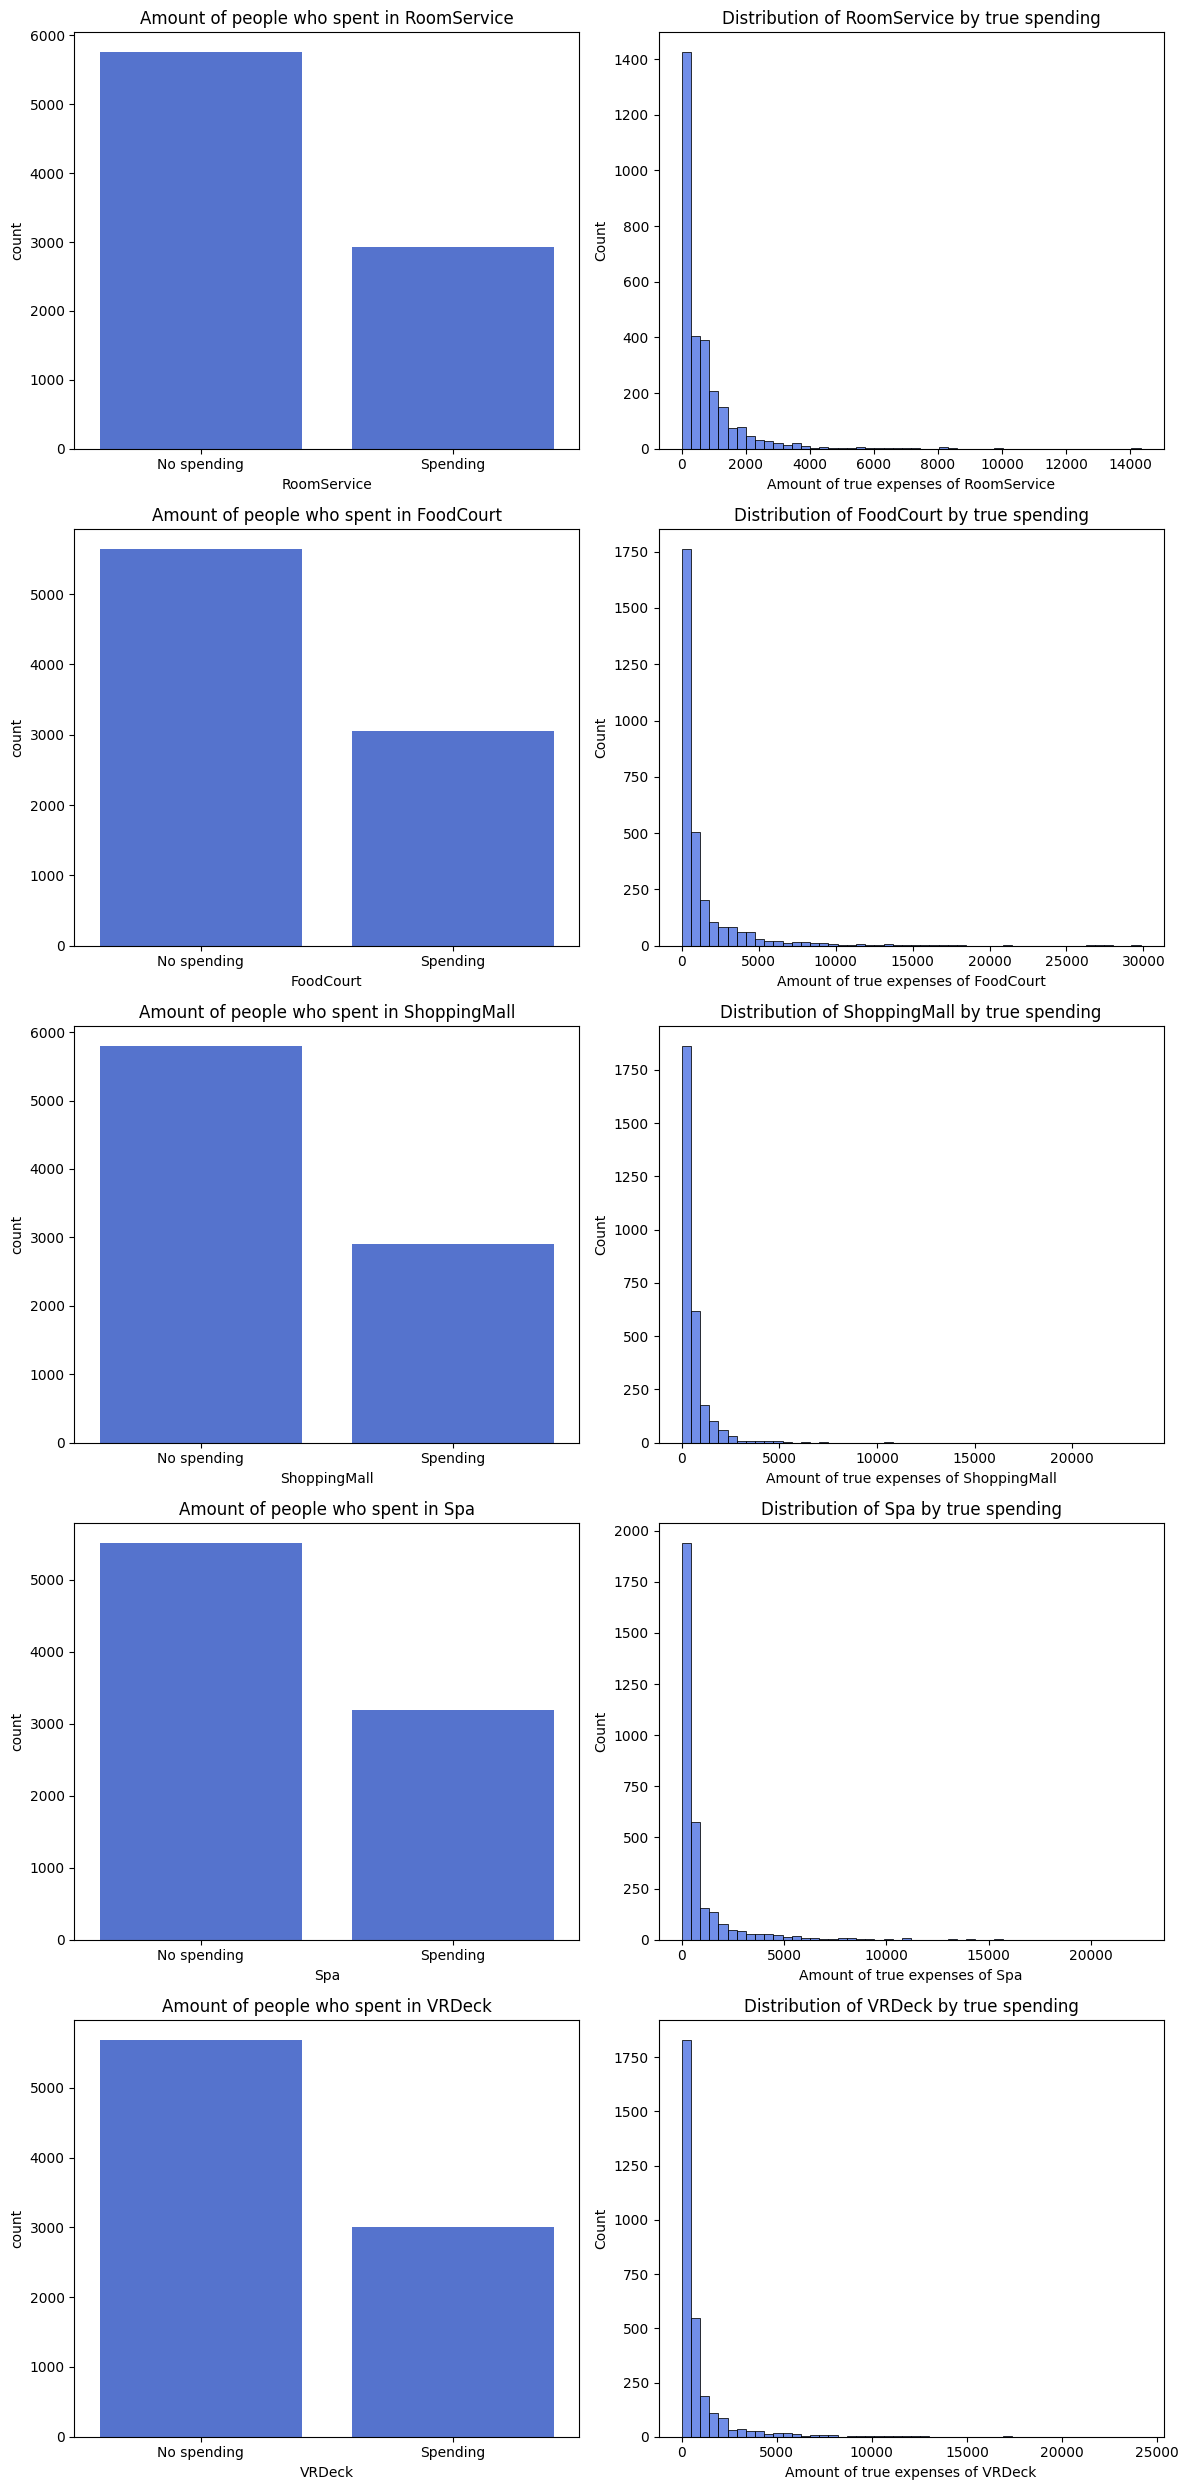

In [65]:
fig, axes = plt.subplots(5, 2, figsize=(12,25))

distrib_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
axes = axes.flatten()
index = 0

for col in distrib_cols:
    sns.countplot(data=df,
                  x=df[col] > 0,
                  ax=axes[index],
                  color='royalblue')
    
    axes[index].set_title(f'Amount of people who spent in {col}')
    axes[index].set_xticks([0, 1])
    axes[index].set_xticklabels(['No spending', 'Spending'])
    index += 1
    
    sns.histplot(data=df[df[col] > 0],
                 x=col,
                 bins=50,
                 color='royalblue',
                 ax=axes[index])
    
    axes[index].set_title(f'Distribution of {col} by true spending')
    axes[index].set_xlabel(f'Amount of true expenses of {col}')
    index += 1

plt.tight_layout()

Выделим выбросы в каждой категории трат:

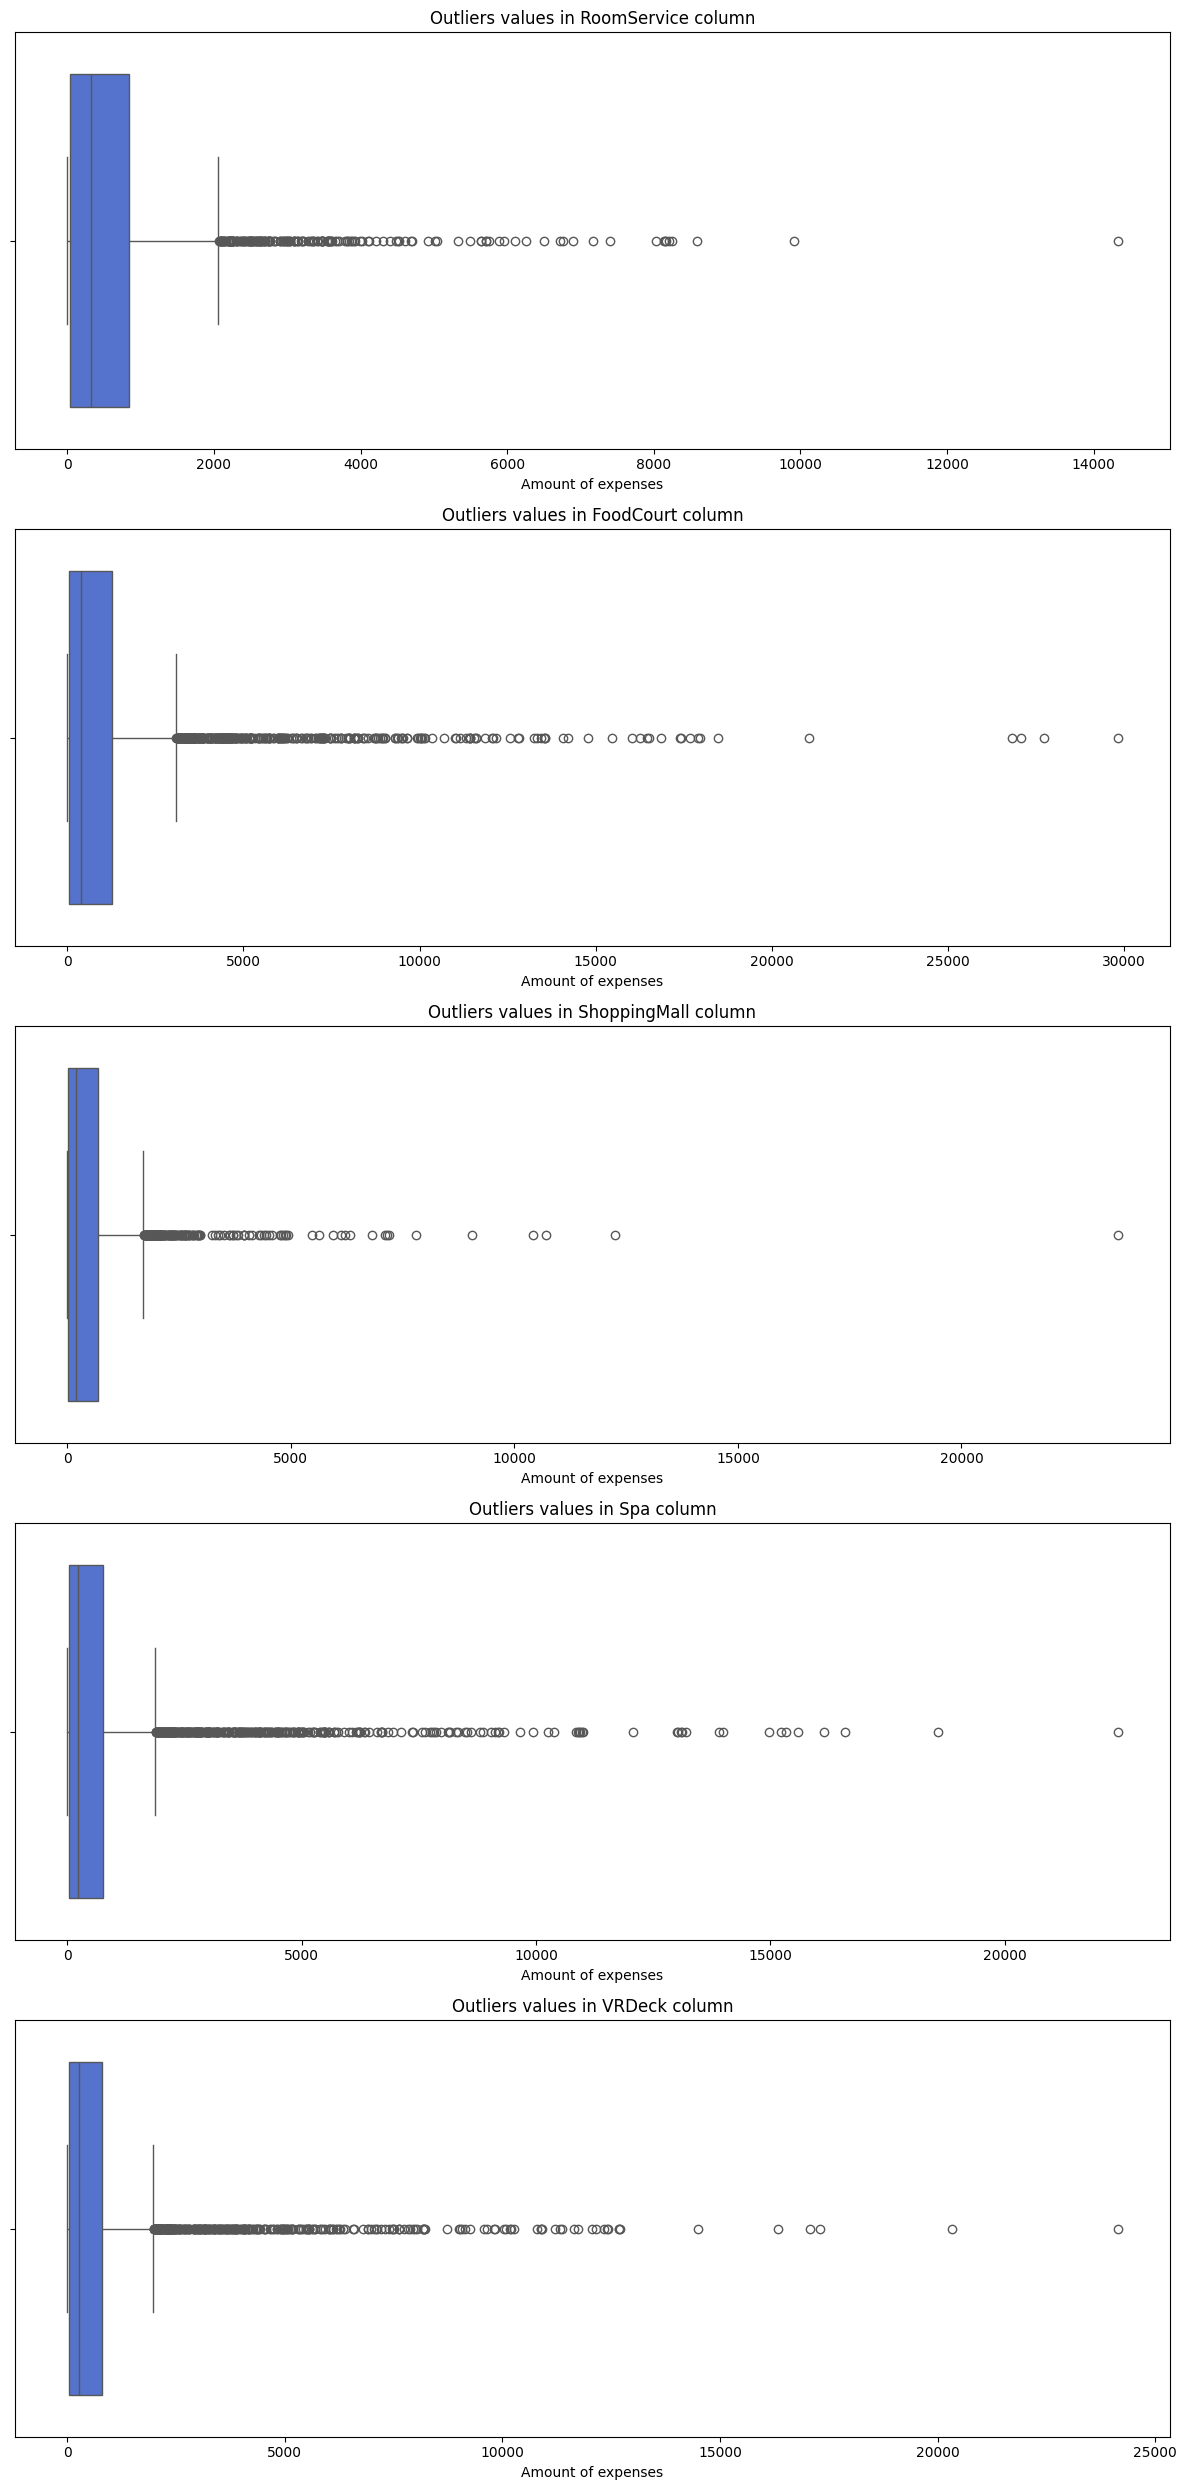

In [66]:
fig, ax = plt.subplots(5, 1, figsize=(12,25))

for index, col in enumerate(distrib_cols):
    sns.boxplot(data=df[df[col] > 0], x=col, color='royalblue', ax=ax[index])
    ax[index].set_title(f'Outliers values in {col} column')
    ax[index].set_xlabel('Amount of expenses')

plt.tight_layout()

Действительно, выделяются серьезные факты трат на разные услуги.

Создадим временный датасет для анализа корреляций, за основу будет взят df:

In [67]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [68]:
corr_cols = ['CryoSleep',
             'Age',
             'VIP',
             'RoomService',
             'FoodCourt',
             'ShoppingMall',
             'Spa',
             'VRDeck',
             'Transported'
            ]

df_corr = df[corr_cols].copy()

for col in ['CryoSleep', 'VIP', 'Transported']:
    df_corr[col] = df_corr[col].astype(float)

df_corr['TotalSpend'] = df_corr[distrib_cols].sum(axis=1)

corr_matrix = df_corr.corr()

После создания признака с общей суммой трат у пассажира, можно оценить зависимость трат от возраста:

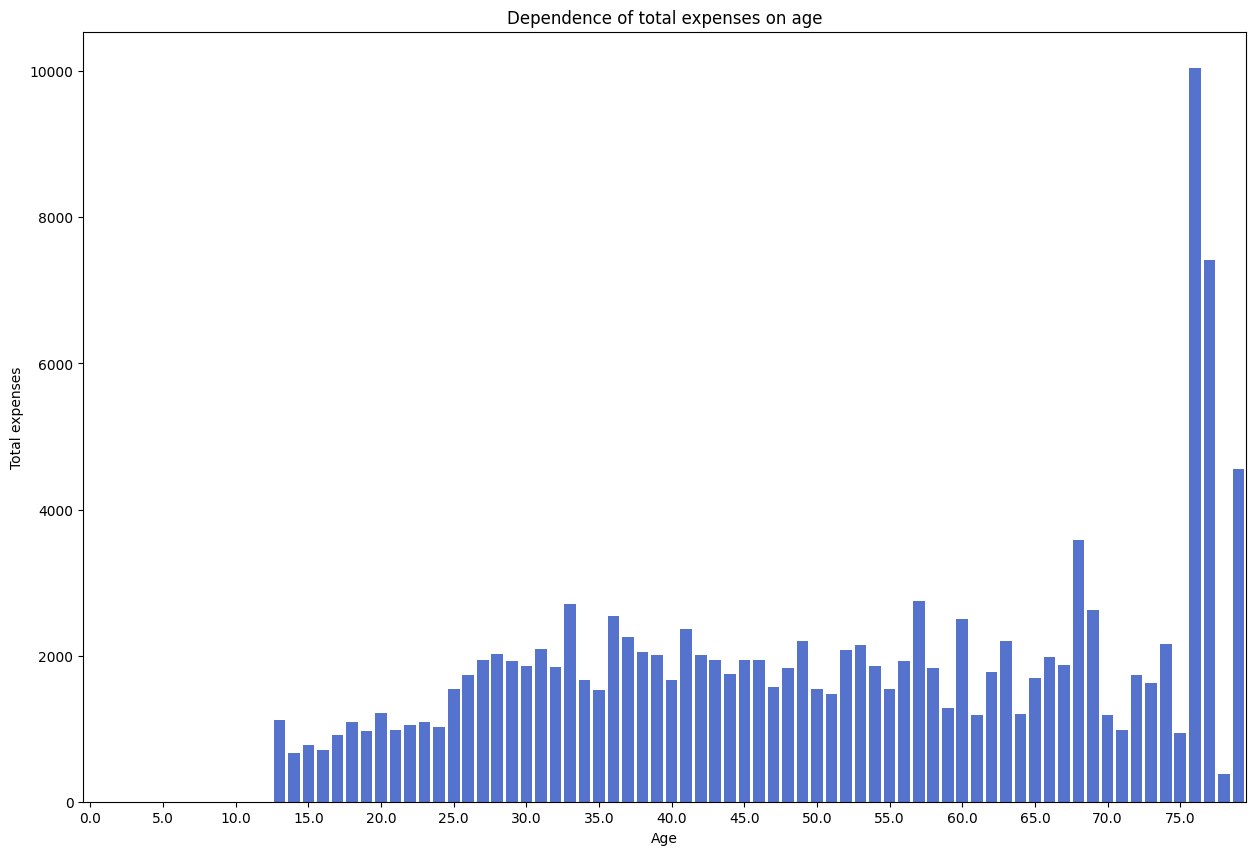

In [69]:
plt.figure(figsize=(15,10))
sns.barplot(data=df_corr, x='Age', y='TotalSpend', errorbar=None, color='royalblue')
plt.title('Dependence of total expenses on age')
plt.xlabel('Age')
plt.ylabel('Total expenses')
plt.xticks(np.arange(0, df_corr['Age'].max() + 1, 5))
plt.show()

Дети с возрастом < 13 не тратили средства, значчит можно выделить отдельный признак IsChild со значением True при Age < 13.

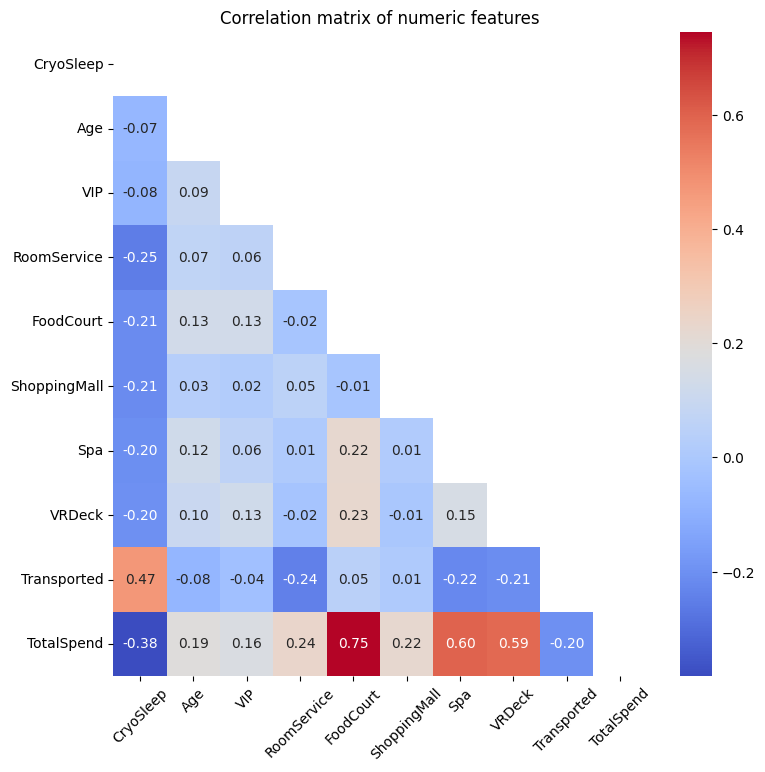

In [70]:
triu_mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8,8))
sns.heatmap(corr_matrix,
            mask=triu_mask,
            cmap='coolwarm',
            annot=True,
            cbar=True,
            fmt='.2f'
           )
plt.title('Correlation matrix of numeric features')
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

Прослеживается негативная корреляция Transported с TotalSpend и особыми группами трат по RoomService, Spa и VRDeck, создадим новый признак NegativeCorrSpend, проссумировав значения в строках по столбцам RoomService, Spa и VRDeck.

Вероятно, этот признак будет иметь более сильную отрицательную корреляцию с Transported, поэтому назовём его так.

В TotalSpend же прослеживается положительная корреляция по этим трём группам и сильная положительная по FoodCourt.

Ещё можно заметить, что те, кто находился во сне, чаще перемещались. А также TotalSpend отрицательно коррелирует с CryoSleep. Вероятно, люди не тратят средства по сне.

Скопируем этот временный датасет и попробуем добавить ещё признаков для анализа корреляций:

In [71]:
df_eda = df_corr.copy()

df_eda['IsChild'] = np.select(
    condlist=[df_eda['Age'] < 13, df_eda['Age'].isna()],
    choicelist=[True, np.nan],
    default=False
)

df_eda['HasSpend'] = np.select(
    condlist=[df_eda['TotalSpend'] > 0, df_eda['TotalSpend'].isna()],
    choicelist=[True, np.nan],
    default=False
)

df_eda['NegativeCorrSpend'] = df_eda[['RoomService', 'Spa', 'VRDeck']].sum(axis=1)

In [72]:
df_eda.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,TotalSpend,IsChild,HasSpend,NegativeCorrSpend
0,0.0,39.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,24.0,0.0,109.0,9.0,25.0,549.0,44.0,1.0,736.0,0.0,1.0,702.0
2,0.0,58.0,1.0,43.0,3576.0,0.0,6715.0,49.0,0.0,10383.0,0.0,1.0,6807.0
3,0.0,33.0,0.0,0.0,1283.0,371.0,3329.0,193.0,0.0,5176.0,0.0,1.0,3522.0
4,0.0,16.0,0.0,303.0,70.0,151.0,565.0,2.0,1.0,1091.0,0.0,1.0,870.0


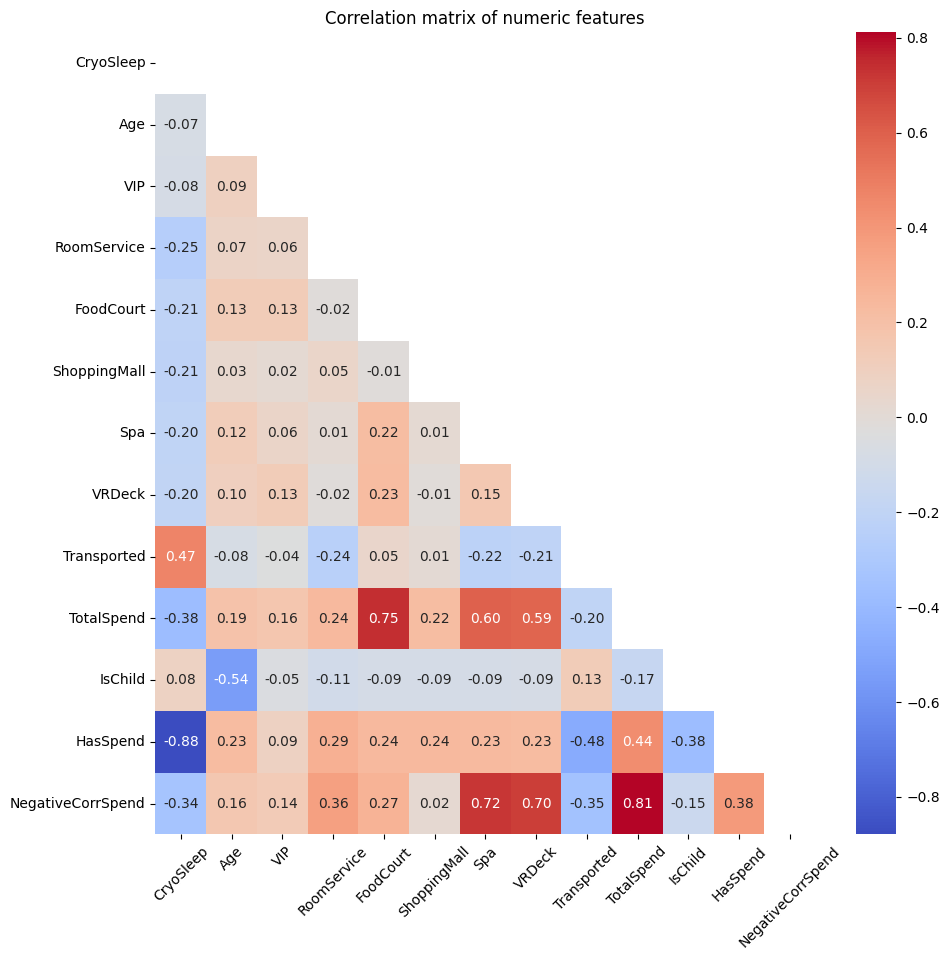

In [73]:
corr_matrix = df_eda.corr()

triu_mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10,10))
sns.heatmap(corr_matrix,
            mask=triu_mask,
            cmap='coolwarm',
            annot=True,
            cbar=True,
            fmt='.2f'
           )
plt.title('Correlation matrix of numeric features')
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

После добавления новых признаков во временный датасет можно оценить их корреляцию с другими:
* Отрицательная корреляция IsChild с Age, это очевидно, ведь первый - это фильтр по условию Age;
* У HasSpend отрицательная корреляция с CryoSleep, значит есть неспящие пассажиры, которые не тратили средства (признаки не прямые дубликаты). В то же время, если пассажир спит, он не может тратить деньги (проверим это кодом ниже). Засчитаем также особую группу пассажиров-экономов;
* HasSpend также считается индикатором для Transported и IsChild. Те, кто тратил, реже перемещались;
* NegativeCorrSpend имеет сильную корреляцию с выбранными для построения признака категориями, это очевидно. Траты в этих областях имеют отрицательную корреляцию с Transported, это в 1.5 раза больше чем просто по TotalSpend -0.20. Также негативная корреляция прослеживается с CryoSleep и и положительная с HasSpend.

Рассмотрим количество пассажиров по условиям спал/не спал и тратил/не тратил и изобразим это в матрице:

In [74]:
print(f'People who spent and sleep (True/True): {len(df_eda[(df_eda['HasSpend'] == 1.0) & (df_eda['CryoSleep'] == 1.0)])}\n')
print(f'People who not spent and not sleep (False/False): {len(df_eda[(df_eda['HasSpend'] == 0.0) & (df_eda['CryoSleep'] == 0.0)])}\n')
print(f'People who not spent and sleep (False/True): {len(df_eda[(df_eda['HasSpend'] == 0.0) & (df_eda['CryoSleep'] == 1.0)])}\n')
print(f'People who spent and not sleep (True/False): {len(df_eda[(df_eda['HasSpend'] == 1.0) & (df_eda['CryoSleep'] == 0.0)])}')

People who spent and sleep (True/True): 0

People who not spent and not sleep (False/False): 518

People who not spent and sleep (False/True): 3037

People who spent and not sleep (True/False): 4921


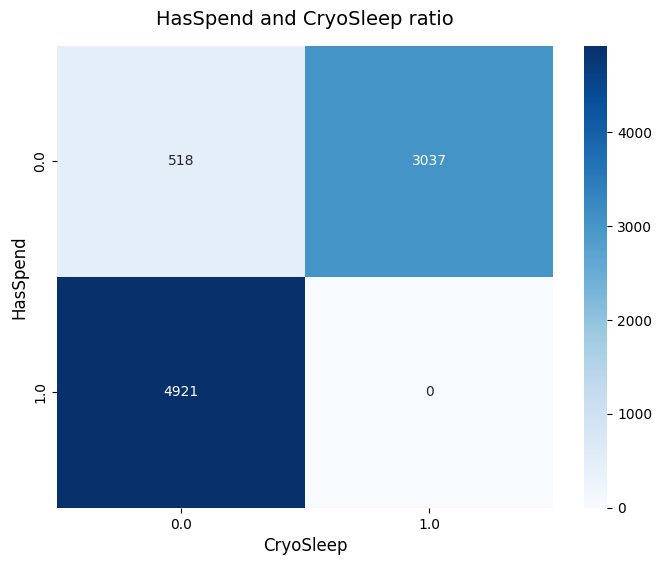

In [75]:
crosstab_matrix = pd.crosstab(df_eda['HasSpend'], df_eda['CryoSleep'], dropna=True)

plt.figure(figsize=(8,6))
sns.heatmap(
    crosstab_matrix, 
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True
)

plt.title('HasSpend and CryoSleep ratio', fontsize=14, pad=15)
plt.xlabel('CryoSleep', fontsize=12)
plt.ylabel('HasSpend', fontsize=12)
plt.show()

Действительно, есть группа пассажиров-экономов. Также прослеживается, что спящий человек не может тратить средства.

# Data preparation

Подготовим данные с помощью кастомных трансформеров для подачи в модели.

In [76]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [77]:
class FeatureEngineeringTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    
    def fit(self, X, y=None):
        return self

    
    def transform(self, X):
        X_out = X.copy()

        passenger_split = X_out['PassengerId'].str.split('_', expand=True)
        
        X_out['GroupId'] = passenger_split[0]
        X_out['GroupSize'] = X_out.groupby('GroupId')['GroupId'].transform('count')
        
        cabin_split = X_out['Cabin'].str.split('/', expand=True)

        X_out['CabinDeck'] = cabin_split[0]
        X_out['CabinNum'] = pd.to_numeric(cabin_split[1], errors='coerce')
        X_out['CabinSide'] = cabin_split[2]

        X_out['TotalSpend'] = X_out[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1)

        X_out['IsChild'] = np.select(
                                    condlist=[X_out['Age'] < 13, X_out['Age'].isna()],
                                    choicelist=[True, np.nan],
                                    default=False
                                    )

        X_out['HasSpend'] = np.select(
                                    condlist=[X_out['TotalSpend'] > 0, X_out['TotalSpend'] <= 0],
                                    choicelist=[True, False]
                                    )

        X_out['NegativeCorrSpend'] = X_out[['RoomService', 'Spa', 'VRDeck']].sum(axis=1)
        
        X_out = X_out.drop(columns=['PassengerId', 'Cabin', 'Name', 'GroupId'])

        return X_out

Трансформер FeatureEngineering нужен для создания признаков из полученного датасета. 

Он добавляет количество людей в группе определенного пассажира, создаёт новые столбцы по кабине пассажира и добавляет признаки, которые участвовали в матрице корреляций на временных датасетах.

Удаляет колонки с ID и те, которые не несут полезную информацию.

На выходе возвращает датасет с новыми признаками.

In [78]:
class DataImputerTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.num_cols = [
            'Age',
            'RoomService',
            'FoodCourt',
            'ShoppingMall',
            'Spa',
            'VRDeck',
            'GroupSize',
            'CabinNum',
            'TotalSpend',
            'NegativeCorrSpend'
        ]

        self.cat_cols = [
            'HomePlanet',
            'Destination',
            'CabinDeck',
            'CabinSide'
        ]

        self.bool_cols = ['CryoSleep', 'VIP']

        self.medians_ = {}
        self.modes_ = {}
        self.encoder_ = OneHotEncoder(sparse_output=False, handle_unknown='ignore')


    def fit(self, X, y=None):
        X_out = X.copy()

        for col in self.num_cols:
            self.medians_[col] = X_out[col].median()

        for col in self.cat_cols:
            self.modes_[col] = X_out[col].mode()[0]

        for col in self.bool_cols:
            self.modes_[col] = X_out[col].mode()[0]

        cat_data = X_out[self.cat_cols].fillna(pd.Series(self.modes_))
        self.encoder_.fit(cat_data) # обучаем энкодер с использованием текущих категориальных мод

        return self


    def transform(self, X):
        X_out = X.copy()

        spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'TotalSpend', 'NegativeCorrSpend']
        cryo_sleep_mask = (X_out['CryoSleep'] == 1) | (X_out['CryoSleep'] == True)
        
        for col in spend_cols:
            X_out.loc[cryo_sleep_mask, col] = 0.0

        spend_mask = (X_out['TotalSpend'] > 0)
        X_out.loc[spend_mask, 'CryoSleep'] = 0.0
         
        for col in self.num_cols:
            X_out[col] = X_out[col].fillna(self.medians_[col])

        X_out['IsChild'] = (X_out['Age'] < 13).astype(float)

        for col in self.cat_cols:
            X_out[col] = X_out[col].fillna(self.modes_[col])

        for col in self.bool_cols:
            X_out[col] = X_out[col].astype(float).fillna(float(self.modes_[col]))

        encoder_array = self.encoder_.transform(X_out[self.cat_cols])
        encoder_cols = self.encoder_.get_feature_names_out(self.cat_cols)
        encoder_df = pd.DataFrame(encoder_array, columns=encoder_cols, index=X_out.index)

        X_out = X_out.drop(columns=self.cat_cols)
        X_out = pd.concat([X_out, encoder_df], axis=1)

        return X_out

Трансформер DataImputer необходим для подсчёта всех медиан и мод, а также обучения энкодера на тренировочных данных.

Он также заполняет пропуски этими медианами и модами, создаёт правила для заполнения рассматриваемых ранее признаков.

На выходе возвращает подготовленный датасет для моделей без пропусков.

# Baseline models training

В качестве baseline-моделей возьмем:
* Random Forest
* LightGBM
* XGBoost
* CatBoost

Проверим их метрику и посчитаем стандартное отклонение.

In [79]:
X = df.drop(columns=['Transported'])

y = df['Transported'].astype(int)

preprocessor = Pipeline([
    ('fe_transformer', FeatureEngineeringTransformer()),
    ('di_transformer', DataImputerTransformer()), 
])

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline_models = {
    'Random Forest': RandomForestClassifier(random_state=42, verbose=0, n_jobs=-1),
    'XGBoost': XGBClassifier(random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

results = []

for name, model in baseline_models.items():
    model_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    scores_CV = cross_val_score(model_pipeline, X, y, scoring='accuracy', cv=CV, n_jobs=-1)

    results.append({
        'Model': name,
        'Accuracy score mean': scores_CV.mean(),
        'Accuracy score std': scores_CV.std()
    })

baseline_table = pd.DataFrame(results).sort_values(by='Accuracy score mean', ascending=False)
display(baseline_table.style.hide(axis='index'))

Model,Accuracy score mean,Accuracy score std
CatBoost,0.815944,0.007368
LightGBM,0.814104,0.001722
Random Forest,0.805245,0.010704
XGBoost,0.804440,0.005556


Берём лучшие модели и отправляем на тестовую выборку. Результаты ниже.

In [80]:
best_baseline_model_cb = Pipeline([
    ('preprocessor', preprocessor),
    ('model', CatBoostClassifier(random_state=42, verbose=0))
])

best_baseline_model_cb.fit(X, y)

test_predict = best_baseline_model_cb.predict(df_test)

submission_cb = pd.DataFrame({
    'PassengerId': df_test['PassengerId'],
    'Transported': test_predict.astype(bool)
})

submission_cb.to_csv('submission_cb.csv', index=False)

In [81]:
best_baseline_model_lgbm = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LGBMClassifier(random_state=42, verbose=0))
])

best_baseline_model_lgbm.fit(X, y)

test_predict = best_baseline_model_lgbm.predict(df_test)

submission_lgbm = pd.DataFrame({
    'PassengerId': df_test['PassengerId'],
    'Transported': test_predict.astype(bool)
})

submission_lgbm.to_csv('submission_lgbm.csv', index=False)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines




| LightGBM Test Score  | CatBoost Test Score  |
| :------------------: | :------------------: |
| 0.80383 (Top 650 ±)  | 0.80710 (Top 300 ±)  |


# Optuna hyperparameters tuning

Подберём гиперпараметры для каждой baseline-модели, сравним и выберем лучшую для отправки на тест.

In [82]:
def get_model(trial, model_name):
    if model_name == 'Random Forest':
        return RandomForestClassifier(
            n_estimators=trial.suggest_int('n_estimators', 50, 500, step=50),
            max_depth=trial.suggest_int('max_depth', 3, 25),
            min_samples_split=trial.suggest_int('min_samples_split', 2, 20),
            min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 20),
            max_features=trial.suggest_categorical(
                'max_features',
                ['sqrt', 'log2', None]
            ),
            
            random_state=42,
            n_jobs=-1
        )

    elif model_name == 'XGBoost':
        return XGBClassifier(
            n_estimators=trial.suggest_int('n_estimators', 50, 500, step=50),
            learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            max_depth=trial.suggest_int('max_depth', 3, 10),
            min_child_weight=trial.suggest_int('min_child_weight', 1, 10),

            reg_alpha=trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),

            random_state=42,
            n_jobs=-1
        )

    elif model_name == 'LightGBM':
        return LGBMClassifier(
            n_estimators=trial.suggest_int('n_estimators', 50, 500, step=50),
            learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            num_leaves=trial.suggest_int('num_leaves', 15, 64),
            min_child_samples=trial.suggest_int('min_child_samples', 5, 100),

            reg_alpha=trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),

            subsample=trial.suggest_float('subsample', 0.6, 1.0),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
            subsample_freq=1,
            
            random_state=42,
            verbose=-1,
            n_jobs=-1
        )

    elif model_name == 'CatBoost':
        return CatBoostClassifier(
            iterations=trial.suggest_int('iterations', 50, 500, step=50),
            learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            depth=trial.suggest_int('depth', 3, 10),
            l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 0.1, 10.0, log=True),
            random_strength=trial.suggest_float('random_strength', 1e-9, 10.0),
            bagging_temperature=trial.suggest_float('bagging_temperature', 0.0, 1.0),

            random_state=42,
            verbose=0,
            thread_count=-1
        )

In [83]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

models_for_testing = ['CatBoost', 'LightGBM', 'Random Forest', 'XGBoost']

results_testing = {}

start_time = time.perf_counter()

for model_name in models_for_testing:
    def objective(trial):
        model = get_model(trial, model_name)
        
        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('model', model)
        ])

        score_CV = cross_val_score(pipeline, X, y, scoring='accuracy', cv=CV, n_jobs=1).mean()

        return score_CV

    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=50)

    results_testing[model_name] = {
        'Best Score': study.best_value,
        'Best Parameters': study.best_params
    }

end_time = time.perf_counter()

all_sec = end_time - start_time
minutes = int(all_sec // 60)
seconds = all_sec % 60
print(f'Optuna hyperparameters tuning took {minutes} minutes {seconds:.3f} seconds')

Optuna hyperparameters tuning took 22 minutes 16.300 seconds


In [84]:
for model_name, info in results_testing.items():
    score = info.get('Best Score', 0)
    params = info.get('Best Parameters', {})
    
    print(f"\n  {model_name} | Best CV Score: {score:.5f}")
    print("-" * 40)
    for p_name, p_val in params.items():
        if isinstance(p_val, float):
            print(f"  • {p_name:<20}: {p_val:.6f}")
        else:
            print(f"  • {p_name:<20}: {p_val}")


  CatBoost | Best CV Score: 0.81778
----------------------------------------
  • iterations          : 350
  • learning_rate       : 0.079892
  • depth               : 5
  • l2_leaf_reg         : 4.604392
  • random_strength     : 2.562193
  • bagging_temperature : 0.869591

  LightGBM | Best CV Score: 0.81629
----------------------------------------
  • n_estimators        : 200
  • learning_rate       : 0.072650
  • num_leaves          : 23
  • min_child_samples   : 26
  • reg_alpha           : 0.001897
  • reg_lambda          : 0.000001
  • subsample           : 0.892789
  • colsample_bytree    : 0.925809

  Random Forest | Best CV Score: 0.80904
----------------------------------------
  • n_estimators        : 150
  • max_depth           : 15
  • min_samples_split   : 8
  • min_samples_leaf    : 6
  • max_features        : None

  XGBoost | Best CV Score: 0.81640
----------------------------------------
  • n_estimators        : 450
  • learning_rate       : 0.037538
  • max_dept

На этот раз берём все 3 бустинга, они друг от друга не сильно отступили по точности.

In [85]:
lgbm_best_params = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LGBMClassifier(**results_testing['LightGBM']['Best Parameters'], random_state=42, verbose=-1))
])

lgbm_best_params.fit(X, y)

lgbm_bp_pred = lgbm_best_params.predict(df_test)

submission_lgbm_bp = pd.DataFrame({
    'PassengerId': df_test['PassengerId'],
    'Transported': lgbm_bp_pred.astype(bool)
})

submission_lgbm_bp.to_csv('submission_lgbm_bp.csv', index=False)

In [86]:
catboost_best_params = Pipeline([
    ('preprocessor', preprocessor),
    ('model', CatBoostClassifier(**results_testing['CatBoost']['Best Parameters'], random_state=42, verbose=0))
])

catboost_best_params.fit(X, y)

catboost_bp_pred = catboost_best_params.predict(df_test)

submission_catboost_bp = pd.DataFrame({
    'PassengerId': df_test['PassengerId'],
    'Transported': catboost_bp_pred.astype(bool)
})

submission_catboost_bp.to_csv('submission_catboost_bp.csv', index=False)

In [87]:
xgb_best_params = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(**results_testing['XGBoost']['Best Parameters'], random_state=42))
])

xgb_best_params.fit(X, y)

xgb_bp_pred = xgb_best_params.predict(df_test)

submission_xgb_bp = pd.DataFrame({
    'PassengerId': df_test['PassengerId'],
    'Transported': xgb_bp_pred.astype(bool)
})

submission_xgb_bp.to_csv('submission_xgb_bp.csv', index=False)

| LightGBM Best Params Test Score  | CatBoost Best Params Test Score  | XGBoost Best Params Test Score  |
| :------------------------------: | :------------------------------: | :-----------------------------: |
| 0.80664 (Top 320 ±)              | 0.80687 (Top 300 ±)              | 0.80243 (Top 720 ±)             |


LightGBM и CatBoost показали результат лучше, чем XGBoost. Посмотрим на важность признаков для этих двух моделей:

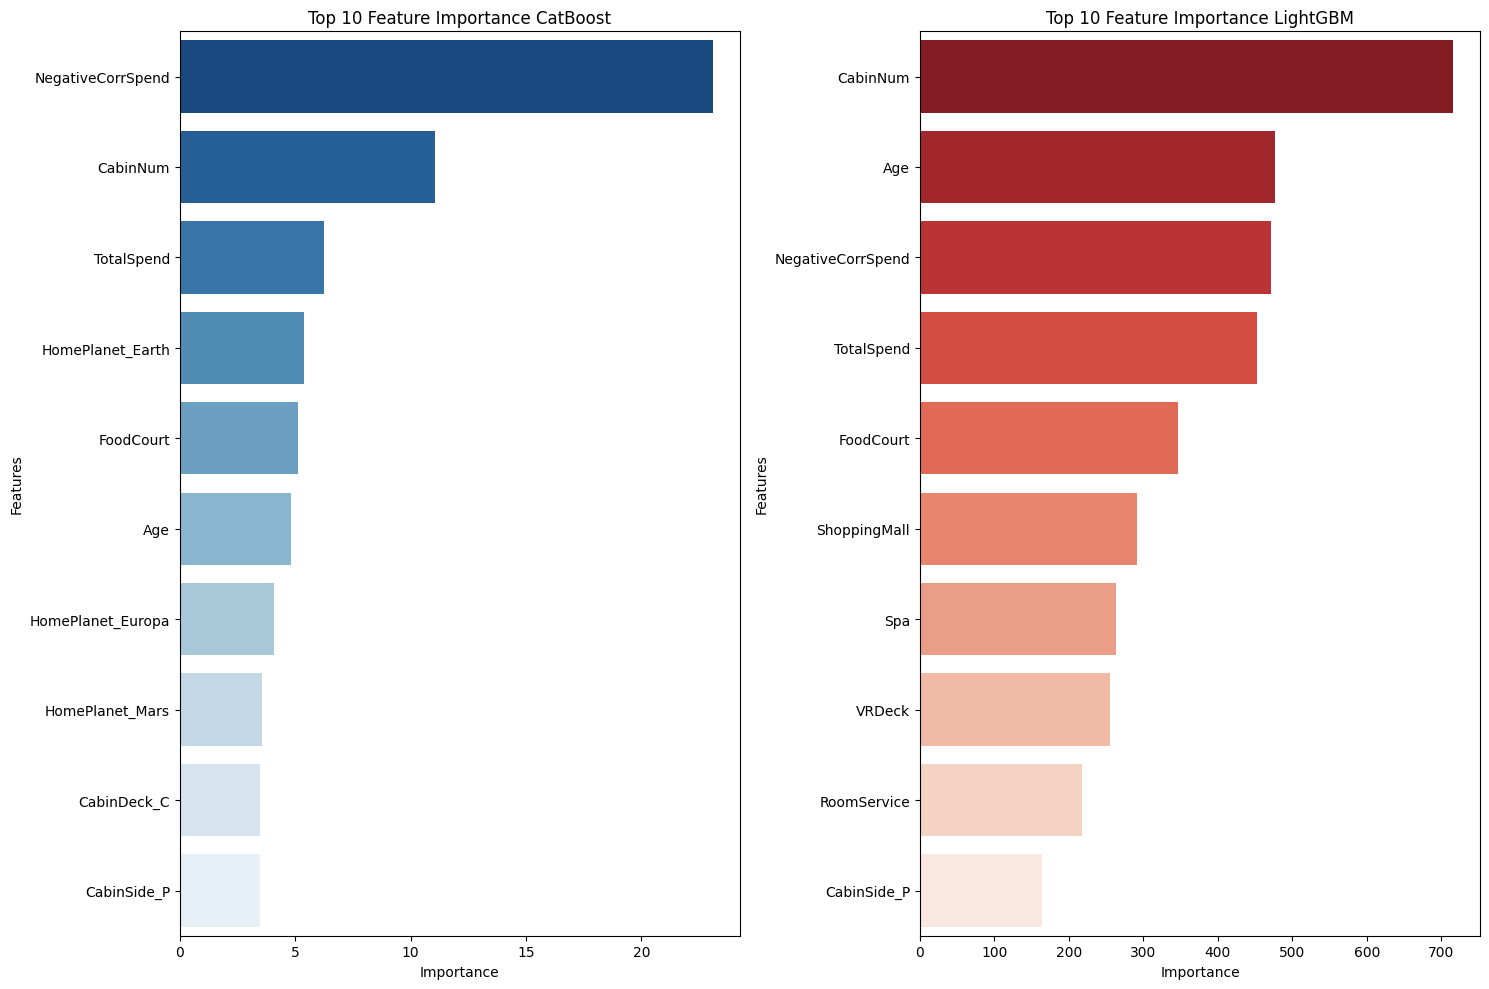

In [88]:
feature_names = catboost_best_params.named_steps['preprocessor'].transform(X.head(1)).columns

cb_model = catboost_best_params.named_steps['model']

df_importance_cb = pd.DataFrame({
    'Features': feature_names,
    'Importance': cb_model.feature_importances_
}).sort_values('Importance', ascending=False)

lgbm_model = lgbm_best_params.named_steps['model']

df_importance_lgbm = pd.DataFrame({
    'Features': feature_names,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 10))

sns.barplot(data=df_importance_cb.head(10), x='Importance', y='Features', ax=axes[0], palette='Blues_r', hue='Features', legend=False)
axes[0].set_title('Top 10 Feature Importance CatBoost')

sns.barplot(data=df_importance_lgbm.head(10), x='Importance', y='Features', ax=axes[1], palette='Reds_r', hue='Features', legend=False)
axes[1].set_title('Top 10 Feature Importance LightGBM')

plt.tight_layout()
plt.show()

Видно, что CatBoost делал упор на сумму с негативной корреляцией (те 3 столбца с сильными тратами), а LightGBM - на номер кабины, в которой находился пассажир.

# Stacking model

Построим модель стекинга на основе 4 baseline-моделей с подобранными гиперпараметрами. Мета-моделью является логистическая регрессия.

In [89]:
start_time = time.perf_counter()

stacking_estimators = [
    ('LightGBM', LGBMClassifier(**results_testing['LightGBM']['Best Parameters'], random_state=42, verbose=-1)),
    ('CatBoost', CatBoostClassifier(**results_testing['CatBoost']['Best Parameters'], random_state=42, verbose=0)),
    ('XGBoost', XGBClassifier(**results_testing['XGBoost']['Best Parameters'], random_state=42)),
    ('Random Forest', RandomForestClassifier(**results_testing['Random Forest']['Best Parameters'], random_state=42))
]

stacking_cls = StackingClassifier(estimators=stacking_estimators, final_estimator=LogisticRegression(random_state=42), cv=CV)

stacking_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', stacking_cls)
])

oof_probs = cross_val_predict(stacking_model, X, y, cv=CV, method='predict_proba')[:, 1]

end_time = time.perf_counter()

all_sec = end_time - start_time
minutes = int(all_sec // 60)
seconds = all_sec % 60
print(f'Building stacking model took {minutes} minutes {seconds:.3f} seconds')

Building stacking model took 3 minutes 59.063 seconds


Можно также подобрать порог, позволяющий увеличить точность стекинга.

In [90]:
base_accuracy = accuracy_score(y, (oof_probs >= 0.5).astype(int))
print(f'Base Accuracy (th = 0.5): {base_accuracy:.5f}')

best_th = 0.5
best_accuracy = base_accuracy

for th in np.arange(0.4, 0.6, 0.005):
    temp_accuracy = accuracy_score(y, (oof_probs >= th).astype(int))
    if temp_accuracy > best_accuracy:
        best_accuracy = temp_accuracy
        best_th = th

print(f'Best "th" parameter: {best_th:.5f}')
print(f'Stacking accuracy: {best_accuracy:.5f}')

Base Accuracy (th = 0.5): 0.81606
Best "th" parameter: 0.52500
Stacking accuracy: 0.81721


In [91]:
stacking_model.fit(X, y)

stacking_probs_test = stacking_model.predict_proba(df_test)[:, 1]

stacking_preds_test = (stacking_probs_test >= best_th)

submission_stacking = pd.DataFrame({
    'PassengerId': df_test['PassengerId'],
    'Transported': stacking_preds_test
})

submission_stacking.to_csv('submission_stacking.csv', index=False)

| Stacking Model Score             |
| :------------------------------: |
| 0.80664 (Top 320 ±)              |

Оценим, как модель распределила веса для каждой baseline-модели:

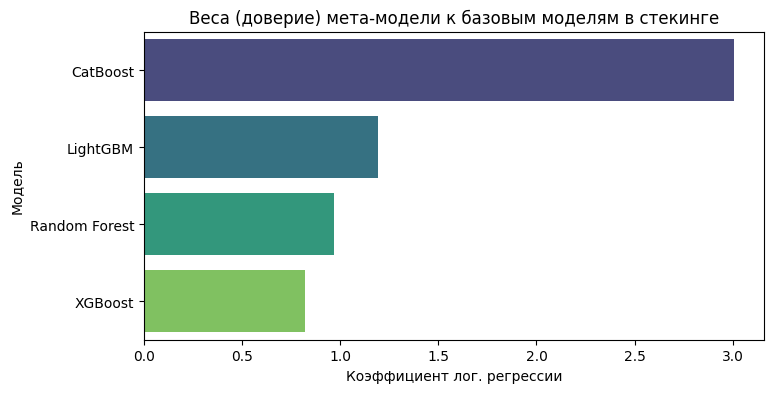

In [92]:
meta_model = stacking_model.named_steps['model'].final_estimator_
model_names = ['LightGBM', 'CatBoost', 'XGBoost', 'Random Forest']
weights = meta_model.coef_[0]

df_weights = pd.DataFrame({
    'Model': model_names,
    'Weight': weights
}).sort_values('Weight', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=df_weights, x='Weight', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('Веса (доверие) мета-модели к базовым моделям в стекинге')
plt.xlabel('Коэффициент лог. регрессии')
plt.ylabel('Модель')
plt.show()


Итоговый скор (accuracy) у стекинга и CatBoost отличился на 0,00046.

С учётом размеров выборок это различие примерно в одного человека.